Treat this notebook as your presentation. No specific structure is given because your project and the way you investigate determines your unique structure.

#### What to include here:
* **Part 1:** Your theoretical report goes here. This section may be as long as you need. You should cover: (1) SVM: a high-level idea, (2) Mathematics behind the model (maximum-margin classification, support vectors, and the kernel trick), (3) Hyper-parameters and how they influence learning, (4) What does a trained model look like (intuitively, mathematically, and programmatically), (5) How does SVM relate to logistic regression?

* **Part 2:** All your experiments. Note that this notebook should only contain the ``front-end'' of your investigation. For example, you load data and visualize some aspects of it. Or, you train a model here and visualize its performance here.

#### What not to include here:
* Any method, class, script that can be implemented outside should be in appropriate scripts. For example, you should implement a `data_loader` method in a `.py` script and only call it here to load the data. Or, you should implement any data pre-processing method in a `.py` script and only call them in this notebook when needed.
___
 

Continue below this cell!


### 1: SVM - a high level idea
Support vector machine (SVM) is a supervised learning algorithm that can be used for classification, regression, and other tasks. For classification, it separates data into different classes by finding a decision boundary with the widest possible margin between them. 

The decision boundary is the optimal hyperplane that separates the different classes and that maximizes the distance between the itself and the nearest training points of each class. These closest data points are called the **support vectors**. They are the only points that determine the position of the boundary. 

The **margin** is the distance between the two parallel boundaries that surround the decision boundary. These boundaries are defined by the support vectors closest to the decision boundary. 

If the decision boundary is written as $w^\top x + b = 0$, the margin has width $2/\Vert w\Vert$, so maximizing the margin is mathematically the same as minimizing $\Vert w\Vert$.

###### Image from scikit learn page. 
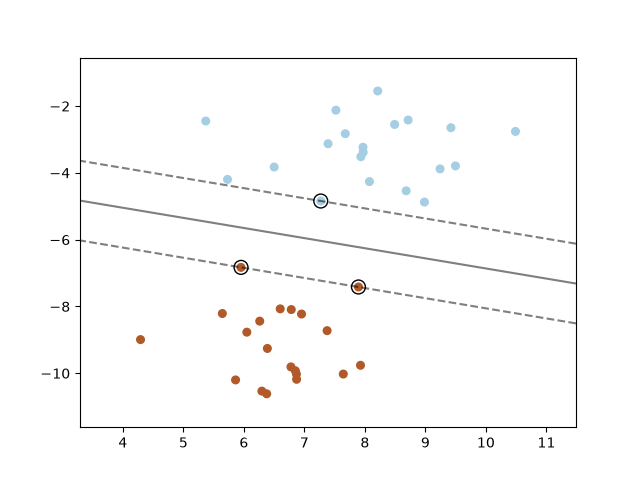

#### Why do we choose the hyperplane with the largest margin? 
For linearly separable data, there are infinitely many boundaries that could perfectly classify the training set, which is why we need a rule for picking the best one. SVM chooses the hyperplane with the largest margin because new data points won't always land in exactly the same positions as the training points did. They might be slightly shifted due to noise or the natural variation of data. A boundary with the largest margin provides a bigger buffer between the classes on each side, making the model less sensitive to small changes and able to tolerate larger shifts before it makes a mistake. This can help the model generalize better to new, unseen data rather than simply memorizing the training observations. 

In most real world cases, since real data is rarely perfectly separable, SVMs use a soft margin and a cost controlled parameter $C$. The support vectors are then samples within the margin boundaries. 

A larger margin also helps control model complexity. Instead of choosing any boundary that separates the training data, SVM looks for one that separates the classes while maintaining the largest possible margin. The margin helps controls how complex the model is, which is an important part of why SVM can perform very well even when the number of features is very large. 





### 2 - Mathematics behind SVM
#### Maximum-Margin Classification
For a binary classification problem, SVM assigns each observations to one of two classes, represented by $(y_i\in{-1,+1})$.

The decision boundary: $w^\top x + b = 0$
where :
- $x$ = feature vector representing an observation
- $w$ = weight vector that determines the orientation of the hyperplane
- $b$ = bias (intercept) that determines the position of the hyperplane

To classify a new observation, SVM calculates a decision score with the decision function: $f(x)=w^\top x + b$

The predictied class is determined by the sign of the result: $\hat{y}=\operatorname{sign}(w^T x+b)$

If the result is positive, the observation is classified as Class +1. If it is negative, it is classified as Class -1. 

Our goal is to find $w \in \mathbb{R}^p$ and $b \in \mathbb{R}$ such that the predicited class is correct for most samples. 

----------------------------------------

#### Maximum-Margin Optimization
As stated before, the goal of SVM is to find the hyperplane that separates the classes while maximizing the margin. The two boundaries surrounding the decision boundary are represented by: 

- $w^\top x + b = +1$
- $w^\top x + b = -1$

The width of the margin is $M=\frac{2}{|w|}$. To maximize the margin, we must minimize the length of the weight vector ${|w|}$. 

This is equivalent to minimizing its squared half: 

$\min_{w,b}\frac{1}{2}{||w||^2}$ 

----------------------------------

##### Hard Margin SVM (Perfectly Separable Data)
For data that can be perfectly separated, the hard-margin SVM optimization problem is: 

$\min_{w,b}\frac{1}{2}w^T w$ 

subject to: $y_i(w^T x_i+b)\geq 1$ for every training observation $i$.

The constraint ensures that every training observation is correctly classified and is on or outside its corresponding margin boundary. However, real-world data is rarely perfectly separable, so requiring every observation to be classified correctly can be very restrictive. 

#### Soft-Margin SVM (Not Perfectly Separable Data)
To handle data that is not perfectly separable, SVM use a soft margin. This allows some observations to fall inside the margin or even be incorrectly classified. 

Slack variables, represented by $\zeta_i$, measure how much each observation violates the margin constraint. 

The soft-margin optimization problem is: 

$ \min_{w,b,\zeta}\frac{1}{2}w^T w+C\sum_{i=1}^{n}\zeta_i$ 

subject to: $y_i(w^T\phi(x_i)+b)\geq 1-\zeta_i$ and $\zeta_i\geq 0$

where: 
- $w$ is the weight vector.
- $b$ is the bias or intercept.
- $\zeta_i$ is the slack variable for observation (i).
- $n$ is the number of training observations.
- $C$ controls how strongly the model penalizes margin violations.
- $\phi(x_i)$ represents the transformation of an observation into the feature space.

The optimization problem has two main goals. The first term, $\frac{1}{2}w^T w$, encourages a larger margin. The second term, $C\sum_{i=1}^{n}\zeta_i$, penalizes observations that violate the margin constraints. SVM balances these two goals when finding the decision boundary.